# Checkpoint 3: Exploratory Data Analysis

| Section | Who |
|---|---|
| 0. Load data | Krish |
| 1. Dataset profiles | Krish |
| 2. Anomalies + cleaning | Krish |
| 3. Distributions | Mahi (Twitter), Dravya (FakeNewsNet + Facebook) |
| 4–6. Relationships, so what, what next | Plot 1 Mahi, Plot 2 Dravya, Plot 3 Krish |
| 7. Revised research questions | Krish (with group) |

## 0. Load data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["font.size"] = 12   # readable axis labels

twitter_daily = pd.read_csv("https://raw.githubusercontent.com/LazerLab/twitter-fake-news-replication/master/figure_1/data/daily_counts_exposures.csv")
twitter_sites = pd.read_csv("https://raw.githubusercontent.com/LazerLab/twitter-fake-news-replication/master/coexposure_network/data/total_exposure_counts.csv")

fake = pd.read_csv("https://raw.githubusercontent.com/KaiDMML/FakeNewsNet/master/dataset/politifact_fake.csv")
real = pd.read_csv("https://raw.githubusercontent.com/KaiDMML/FakeNewsNet/master/dataset/politifact_real.csv")
fake["label"] = "fake"
real["label"] = "real"
news = pd.concat([fake, real], ignore_index=True)

facebook = pd.read_csv("https://raw.githubusercontent.com/BuzzFeedNews/2016-10-facebook-fact-check/master/data/facebook-fact-check.csv")
ratings = pd.read_csv("https://raw.githubusercontent.com/hauselin/domain-quality-ratings/main/data/domain_pc1.csv")

## 1. Dataset profiles

We use pandas, so `df.info()` plays the role of `glimpse()`/`schema`, and `df.isna().sum()` plays the role of `null_count()`.

### Primary 1a: Twitter daily counts

In [2]:
print(twitter_daily.shape)
twitter_daily.info()

(128, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 128 entries, 0 to 127
Data columns (total 10 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   ts_rel_days  128 non-null    int64  
 1   red          128 non-null    int64  
 2   orange       128 non-null    int64  
 3   black        128 non-null    int64  
 4   N            128 non-null    int64  
 5   date         128 non-null    object 
 6   pct_red      128 non-null    float64
 7   pct_orange   128 non-null    float64
 8   pct_black    128 non-null    float64
 9   pct_fake     128 non-null    float64
dtypes: float64(4), int64(5), object(1)
memory usage: 10.1+ KB


In [3]:
twitter_daily.isna().sum()

ts_rel_days    0
red            0
orange         0
black          0
N              0
date           0
pct_red        0
pct_orange     0
pct_black      0
pct_fake       0
dtype: int64

In [4]:
twitter_daily.describe()

,ts_rel_days,red,orange,black,N,pct_red,pct_orange,pct_black,pct_fake
count,128.000000,128.000000,128.000000,128.000000,1.280000e+02,128.000000,128.000000,128.000000,128.000000
mean,-35.500000,11984.835938,9164.320312,3286.625000,4.934006e+05,0.025440,0.019494,0.007043,0.051978
std,37.094474,3820.934469,2793.924308,1363.460621,1.931745e+05,0.006002,0.004606,0.002681,0.012315
min,-99.000000,6390.000000,4250.000000,1315.000000,2.383320e+05,0.009457,0.008363,0.001411,0.019231
25%,-67.250000,8950.250000,7196.000000,2219.500000,3.852392e+05,0.021752,0.016302,0.005028,0.044212
50%,-35.500000,10801.500000,8735.500000,2683.000000,4.507975e+05,0.025368,0.019337,0.006466,0.051489
75%,-3.750000,13439.750000,10288.000000,4259.500000,5.718202e+05,0.029434,0.022525,0.008514,0.059443
max,28.000000,20738.000000,17813.000000,6110.000000,1.514602e+06,0.045792,0.032337,0.013770,0.082507


**What stands out:**
- 128 rows, one per day, with no missing values at all.
- `date` is stored as text (`object`), not a date. We fix this in Section 2.
- `N` (total news views per day) ranges from about 238,000 to 1.5 million. The two biggest days are Nov 8 and Nov 9, election day and the day after.
- `pct_fake` averages 5.2% and stays between 1.9% and 8.3%. So fake news was a small share of news views on every day.

### Primary 1b: Twitter website totals

In [5]:
print(twitter_sites.shape)
twitter_sites.info()

(606, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 606 entries, 0 to 605
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   website  606 non-null    object
 1   N        606 non-null    int64 
dtypes: int64(1), object(1)
memory usage: 9.6+ KB


In [6]:
twitter_sites.isna().sum()

website    0
N          0
dtype: int64

In [7]:
twitter_sites.describe()

,N
count,6.060000e+02
mean,7.079508e+04
std,2.540429e+05
min,4.700000e+01
25%,2.331750e+03
50%,7.701000e+03
75%,3.011975e+04
max,3.404953e+06


**What stands out:**
- 606 websites, with no missing values and no repeated websites.
- `N` is extremely skewed. The mean (about 70,800) is about 9 times the median (about 7,700), because a few sites like nytimes.com (3.4 million) are much bigger than the rest. We'll need log scales to plot it.

### Primary 2: FakeNewsNet (PolitiFact)

In [8]:
print(news.shape)
news.info()

(1056, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1056 entries, 0 to 1055
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         1056 non-null   object
 1   news_url   995 non-null    object
 2   title      1056 non-null   object
 3   tweet_ids  801 non-null    object
 4   label      1056 non-null   object
dtypes: object(5)
memory usage: 41.4+ KB


In [9]:
news.isna().sum()

id             0
news_url      61
title          0
tweet_ids    255
label          0
dtype: int64

In [10]:
# number of tweets that shared each article
news["num_tweets"] = news["tweet_ids"].str.split().str.len()
news.describe()

,num_tweets
count,801.000000
mean,728.484395
std,2415.379702
min,1.000000
25%,14.000000
50%,84.000000
75%,486.000000
max,29060.000000


In [11]:
news.groupby("label")["num_tweets"].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
fake,392.0,421.816327,1810.121786,1.0,23.75,102.0,326.0,29060.0
real,409.0,1022.405868,2849.974457,1.0,8.00,58.0,929.0,27377.0


**What stands out:**
- 1,056 articles (432 fake, 624 real), but 255 have no tweet IDs and 61 have no URL.
- `num_tweets` is very skewed. For fake articles the median is 102 but the mean is 422, and the max is 29,060.
- **Surprise:** fake articles have a *higher median* tweet count than real ones (102 vs 58), but a *lower mean* (422 vs 1,022). So the answer to "does fake news spread more?" depends on which statistic we use. A few very viral real articles pull the real mean up.
- The most-tweeted "article" is titled "The Legislative Process", which does not look like a news story. This led us to the junk rows in Section 2.

## 2. Anomalies

| # | Dataset | Anomaly | Rows affected | What we did |
|---|---|---|---|---|
| 1 | Twitter daily | `date` stored as text instead of a date | all 128 | **Fixed:** converted with `pd.to_datetime` |
| 2 | Twitter daily | Checked for missing days and for `pct_fake` ≠ (red+orange+black)/N | 0 | Nothing to fix: no gaps, and the percentages match the counts |
| 3 | Twitter sites | Subdomains (like `motto.time.com`) don't match their parent domain in the ratings data | 72 sites don't join (1.6% of views) | **Left and flagged:** they are a small share of views |
| 4 | FakeNewsNet | Same article ID labeled **both** fake and real | 2 IDs (4 rows) | **Dropped:** we can't trust the label |
| 5 | FakeNewsNet | Junk pages instead of news (e.g. "Account Suspended", "website is for sale", the MSN homepage) | 20 rows | **Dropped** |
| 6 | FakeNewsNet | No tweet IDs | 255 rows | **Fixed:** set `num_tweets` to 0, since no tweets were found |
| 7 | FakeNewsNet | Missing `news_url` | 61 rows | **Left and flagged:** we don't need the URL for tweet counts |
| 8 | FakeNewsNet | Inconsistent URL format: some lack `http`, many are web.archive.org copies | 80 lack `http`; 196 archive links | **Left and flagged:** this only matters if we join on domain later |
| 9 | FakeNewsNet | Very large tweet counts (up to 29,060) | a few rows | **Kept:** these are real viral articles, but we use medians and log scales |

In [12]:
# Anomaly 1: date stored as text -> datetime
twitter_daily["date"] = pd.to_datetime(twitter_daily["date"])
twitter_daily = twitter_daily.sort_values("date")

# Anomaly 2: check for missing days, and that pct_fake matches the counts
all_days = pd.date_range(twitter_daily["date"].min(), twitter_daily["date"].max())
print("missing days:", len(all_days) - twitter_daily["date"].nunique())
check = (twitter_daily["red"] + twitter_daily["orange"] + twitter_daily["black"]) / twitter_daily["N"]
print("rows where pct_fake doesn't match:", ((check - twitter_daily["pct_fake"]).abs() > 0.000001).sum())

missing days: 0
rows where pct_fake doesn't match: 0


In [13]:
# Anomaly 3: Twitter websites with no quality rating
no_rating = twitter_sites[~twitter_sites["website"].isin(ratings["domain"])]
print(len(no_rating), "sites have no rating")
print("share of all views:", round(no_rating["N"].sum() / twitter_sites["N"].sum() * 100, 1), "%")
no_rating.sort_values("N", ascending=False).head()

72 sites have no rating
share of all views: 1.6 %


,website,N
414,twentytwowords.com,170691
467,tacticalinvestor.com,70993
380,motto.time.com,42146
323,1.001.free.fr,41501
157,lawnewz.com,28214


In [14]:
# Anomaly 4: same id labeled both fake and real
dup_ids = news[news["id"].duplicated(keep=False)]
print(len(dup_ids), "rows")
dup_ids[["id", "label", "title"]]

4 rows


,id,label,title
42,politifact14940,fake,Full text: Jeff Flake on Trump speech transcript
309,politifact14920,fake,eCFR — Code of Federal Regulations
519,politifact14940,real,Full text: Jeff Flake on Trump speech transcript
881,politifact14920,real,eCFR — Code of Federal Regulations


In [15]:
# Anomaly 5: junk pages that aren't news articles
junk_words = "Account Suspended|under construction|for sale|Outlook, Office, Skype"
junk = news["title"].str.contains(junk_words, case=False)
print(junk.sum(), "junk rows")
news.loc[junk, "title"].value_counts()

20 junk rows


title
Outlook, Office, Skype, Bing, Breaking News, and Latest Videos                                     13
Account Suspended                                                                                   3
American News is under construction                                                                 2
UsPostman.com is for sale (Us Postman)                                                              1
trueamericans.me -&nbspThis website is for sale! -&nbsptrueamericans Resources and Information.     1
Name: count, dtype: int64

In [16]:
# Cleaning: drop anomalies 4 and 5, fix anomaly 6
news_clean = news[~news["id"].isin(dup_ids["id"]) & ~junk].copy()
news_clean["num_tweets"] = news_clean["num_tweets"].fillna(0)

print("before:", news.shape, " after:", news_clean.shape)
news_clean["label"].value_counts()

before: (1056, 6)  after: (1032, 6)


label
real    609
fake    423
Name: count, dtype: int64

In [17]:
# Anomalies 7 and 8: flagged, not fixed
print("missing url:", news_clean["news_url"].isna().sum())
print("url without http:", (~news_clean["news_url"].dropna().str.startswith("http")).sum())
print("web.archive.org url:", news_clean["news_url"].dropna().str.contains("web.archive.org").sum())

missing url: 61
url without http: 80
web.archive.org url: 196


## 3. Distributions

For each feature, describe the **center, spread, skew, and outliers**.

### Twitter features (Mahi)
TODO Mahi: histogram of `pct_fake` and histogram of `N` from `twitter_daily`, each with a title and axis labels, and 2–3 sentences describing each shape.

In [18]:
# Mahi: pct_fake histogram


In [19]:
# Mahi: N histogram


### FakeNewsNet and Facebook features (Dravya)
TODO Dravya: histogram of `num_tweets` from `news_clean` (use a log scale, because it is very skewed), and a bar chart of counts of `Rating` from `facebook`, each with a title and axis labels, and 2–3 sentences describing each shape.

In [20]:
# Dravya: num_tweets histogram


In [21]:
# Dravya: Facebook Rating counts


## 4–6. Relationships, so what, and what next

### Plot 1: (Mahi) How did the fake-news share change over time?
TODO Mahi: move your `pct_fake` over-time chart here (with the election day line). Also add a second chart: `N` vs `pct_fake` as a scatter, OR `pct_fake` on weekdays vs weekends as a box plot.

**So what:** TODO

**Expected or unexpected?** TODO

**What next:** TODO

In [22]:
# Mahi: plot 1


### Plot 2: (Dravya) Do fake articles get more tweets than real ones?
TODO Dravya: box plot of `num_tweets` by `label` (use a log scale) from `news_clean`. Also compare it with Facebook: median `share_count` by `Rating`. This is the comparison with our secondary dataset.

**So what:** TODO

**Expected or unexpected?** TODO

**What next:** TODO

In [23]:
# Dravya: plot 2


### Plot 3: (Krish) Do low-quality websites get more Twitter views? *(join with secondary dataset)*

We join the Twitter website totals with the website quality ratings on the website name.

(534, 4)


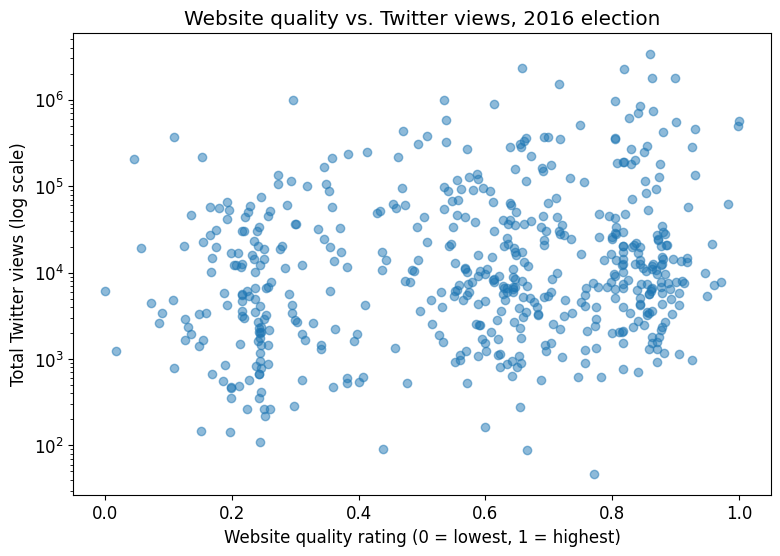

In [24]:
joined = twitter_sites.merge(ratings, left_on="website", right_on="domain")
print(joined.shape)

plt.figure(figsize=(9, 6))
plt.scatter(joined["pc1"], joined["N"], alpha=0.5)
plt.yscale("log")
plt.xlabel("Website quality rating (0 = lowest, 1 = highest)")
plt.ylabel("Total Twitter views (log scale)")
plt.title("Website quality vs. Twitter views, 2016 election")
plt.show()

In [25]:
# group websites into low / medium / high quality and compare
joined["quality"] = pd.cut(joined["pc1"], bins=[0, 0.4, 0.7, 1], labels=["low", "medium", "high"], include_lowest=True)
summary = joined.groupby("quality", observed=True)["N"].agg(["count", "median", "sum"])
summary["share_of_views_%"] = (summary["sum"] / summary["sum"].sum() * 100).round(1)
summary

,count,median,sum,share_of_views_%
quality,,,,
low,155,5304.0,4821462,11.4
medium,183,10187.0,13422483,31.8
high,196,11184.5,23972667,56.8


In [26]:
# correlation (spearman, because N is very skewed)
print("spearman correlation:", round(joined["pc1"].corr(joined["N"], method="spearman"), 2))

# the low-quality sites that still got lots of views
joined[joined["quality"] == "low"].sort_values("N", ascending=False).head(5)

ModuleNotFoundError: No module named 'scipy'

**So what:** Higher-quality websites got somewhat *more* Twitter views, not fewer. Low-quality sites (rating under 0.4) make up 155 of the 534 matched websites, but only about 11% of all views. The correlation is weak (Spearman ≈ 0.17), and there is a lot of spread: a few low-quality sites got huge audiences: breitbart.com had about 1 million views and thegatewaypundit.com about 370,000. So on Twitter in 2016, low-quality news was a small part of what people saw overall. But a few low-quality sites were as big as mainstream outlets.

**Expected or unexpected?** Somewhere in between. Headlines like "fake news spreads faster" made us expect low-quality sites to win. Instead, the total views went mostly to mainstream, high-quality sites. This matches the original Grinberg et al. finding that fake news was concentrated in a small number of sites and users.

**What next:** Total views mix two things: how *popular* a site is and how *viral* each story is. Next we want to look at views per article, or split by the site's political lean (the Grinberg data has alignment scores), to see if low-quality sites do better within one side. A journalism or media-studies expert could also help us understand why a few low-quality sites got so big.

## 7. Revised research questions

| Before | After | What changed and why |
|---|---|---|
| Does fake news get shared more than real news on social media? | Is the **typical** fake article shared more than the typical real article, and are the **most viral** stories fake or real? | The median and the mean disagreed (Section 1), so "more" has to be split into typical vs. extreme sharing. |
| How much Twitter news came from fake-news sites, and did that change near election day? | How did the fake-news share change **over time and by day of week**, and does it shrink on big news days? | *(Mahi: update after Plot 1)* |
| Do low-quality news websites get more attention than high-quality ones? | Is low-quality news **concentrated in a few sites**, and do those sites get more attention **per story** than high-quality sites? | Plot 3 showed that low-quality sites get fewer total views overall, but a few are huge, so the interesting question is concentration, not the average. |